# 03 · Descriptive statistics and identity sensitivity

Measure associations between recorded fields and evaluate how changing the row selection changes a lighting comparison. Values refer to workbook records with positive numeric fatality counts.

[Previous](02_eda_statistics_and_visualization.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](04_data_suitability.ipynb)

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from bd_safety.statistics import conditional_cluster_interval, night_day_effect
from IPython.display import Image, display
from scipy.stats import chi2_contingency, spearmanr

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/bd_safety").is_dir(), (
    "Open from the project root or notebooks directory."
)
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"


fields = [
    "fatal_record",
    "fatalities",
    "injuries",
    "lighting",
    "source_id",
    "descriptor_group",
]
records = pd.read_csv(ROOT / "data/processed/cleaned_records.csv", usecols=fields)
stats = json.loads((REPORTS / "statistics.json").read_text())

## How strongly do the recorded fields vary together?

Build a contingency table to calculate Cramér’s V for lighting and the positive fatality-count flag. Use Spearman’s rank correlation for the two recorded casualty counts. Inspect the statistics without making independent-event inference.

In [2]:
counts = pd.crosstab(records["lighting"], records["fatal_record"])
chi_squared, _, _, expected = chi2_contingency(counts, correction=False)
cramers_v = np.sqrt(chi_squared / (counts.to_numpy().sum() * (min(counts.shape) - 1)))
rho = spearmanr(records["fatalities"], records["injuries"]).statistic
lighting = next(
    row for row in stats["descriptive_effects"] if row["field"] == "lighting"
)
assert np.isclose(cramers_v, lighting["cramers_v"])
assert np.isclose(rho, stats["fatality_injury_spearman_rho"])
display(counts)
display(
    pd.Series(
        {
            "lighting Cramér’s V": cramers_v,
            "casualty-count Spearman rho": rho,
            "minimum expected lighting cell": expected.min(),
        }
    )
)

fatal_record,0,1
lighting,,
Dawn,833,1637
Day,7478,15416
Dusk,3200,6195
Night,4309,8608


lighting Cramér’s V                 0.011728
casualty-count Spearman rho        -0.000879
minimum expected lighting cell    819.603155
dtype: float64

The associations are small for these recorded fields. Uncertain incident identity and conflicting measurements prevent treating workbook rows as independent events.

## How does the recorded Night–Day comparison vary under resampling?

Calculate the fraction of positive-count rows within each label. Resample descriptor groups as computational clusters with the original fixed seed and 2,000 replicates.

In [3]:
lighting_rows = records.loc[records["lighting"].isin(["Day", "Night"])]
summary = lighting_rows.groupby("lighting")["fatal_record"].agg(
    records="size", positive_share="mean"
)
gap = summary.at["Night", "positive_share"] - summary.at["Day", "positive_share"]
assert np.isclose(gap, stats["night_day_effect"]["difference_night_minus_day"])
interval = conditional_cluster_interval(records)
np.testing.assert_allclose(
    [interval["lower"], interval["upper"]],
    [stats["conditional_bootstrap"]["lower"], stats["conditional_bootstrap"]["upper"]],
)
display(summary)
display(
    pd.Series(
        {
            "gap_pp": gap * 100,
            "lower_pp": interval["lower"] * 100,
            "upper_pp": interval["upper"] * 100,
        }
    ).round(2)
)

,records,positive_share
lighting,,
Day,22894,0.673364
Night,12917,0.666409


gap_pp     -0.70
lower_pp   -1.78
upper_pp    0.29
dtype: float64

The Night-minus-Day difference is −0.70 percentage points and the conditional reference interval runs from −1.78 to +0.29. It describes resampling under the candidate grouping. Verified incidents, exposure and a defensible sampling frame would be needed for population inference.

## Does the direction survive a different row selection?

Apply the audited first- and last-record selection rules in source order. Compare all four gaps to the original sensitivity export.

,scenario,records,night_minus_day_pp
0,Exact-row deduplication only,47676,-0.70
1,One earliest row per source ID (unverified ide...,17497,0.24
2,One earliest row per descriptor group (unverif...,2321,-1.80
3,One latest row per descriptor group (unverifie...,2321,1.35


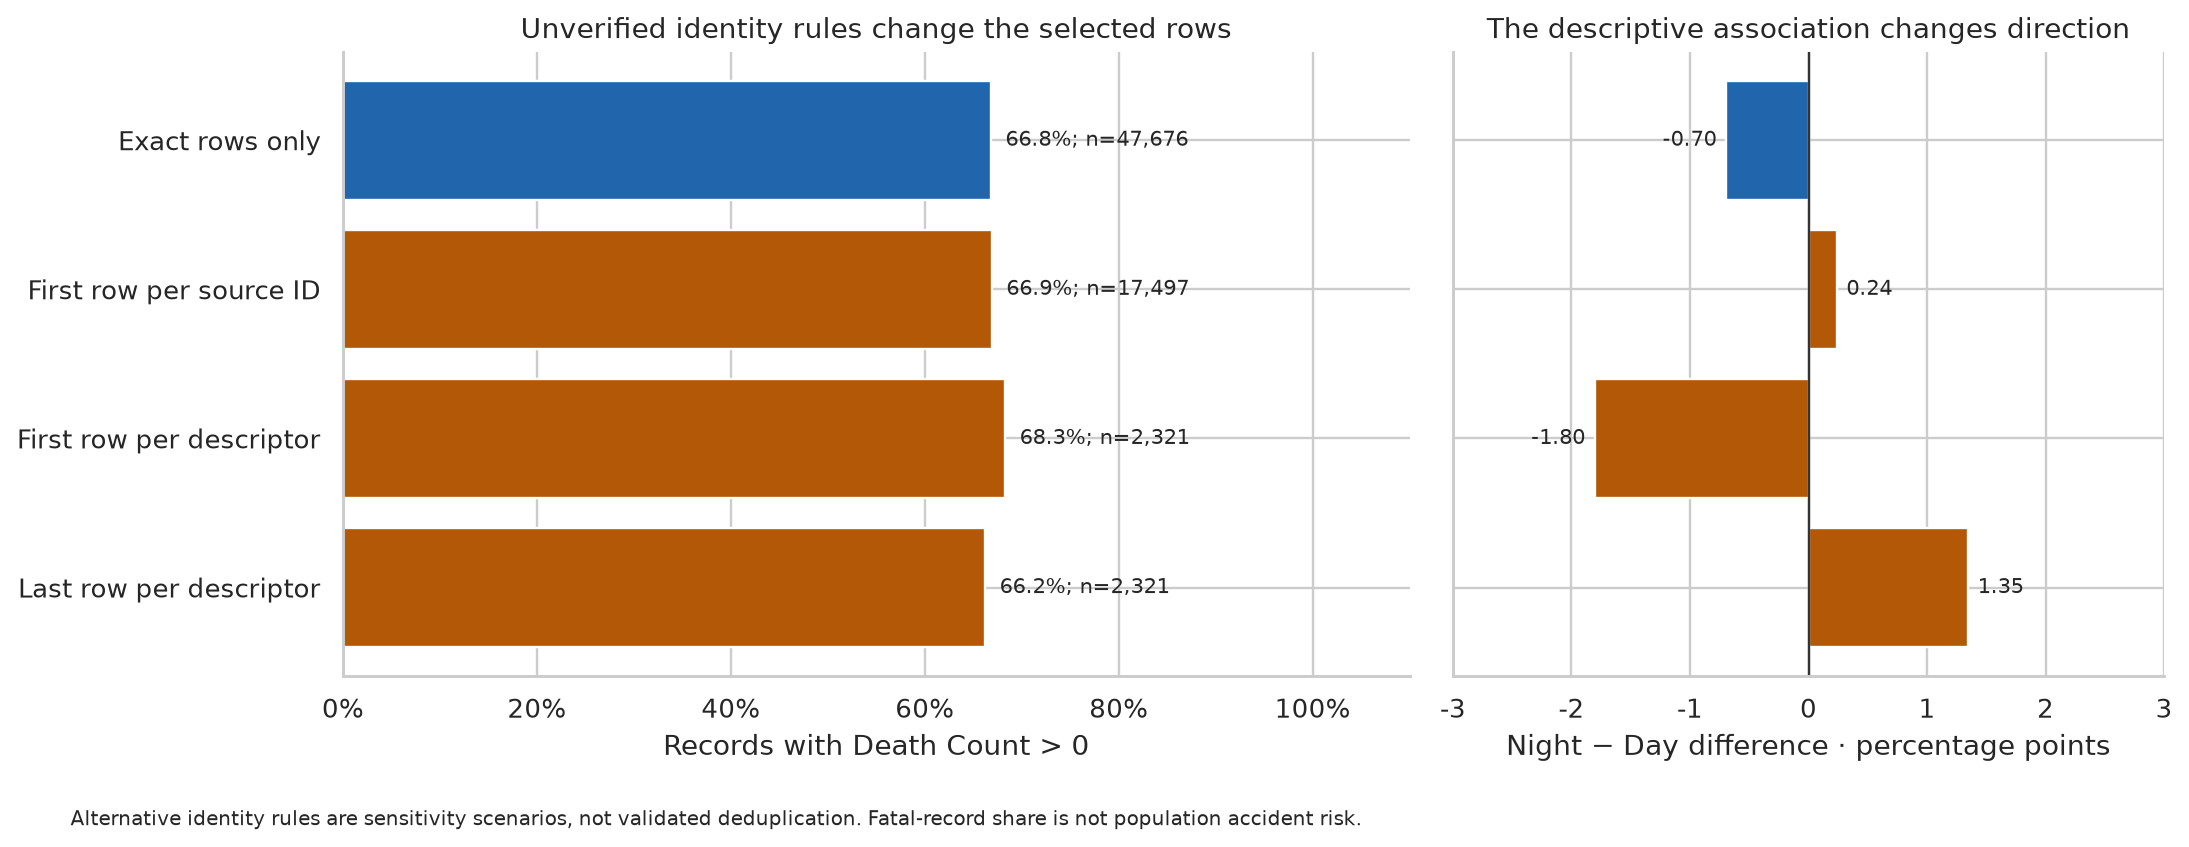

In [4]:
alternatives = [
    records,
    records.drop_duplicates("source_id"),
    records.drop_duplicates("descriptor_group"),
    records.drop_duplicates("descriptor_group", keep="last"),
]
differences = [
    night_day_effect(frame)["difference_night_minus_day"] for frame in alternatives
]
saved = pd.read_csv(TABLES / "duplicate_sensitivity.csv")
np.testing.assert_allclose(differences, saved["difference_night_minus_day"])
display(
    saved[["scenario", "records"]].assign(
        night_minus_day_pp=np.round(np.array(differences) * 100, 2)
    )
)
display(
    Image(filename=str(REPORTS / "figures/10_duplicate_sensitivity.png"), width=900)
)

Selecting the first versus last row per candidate descriptor group reverses the gap from −1.80 to +1.35 points. This instability matters more for the suitability decision than the precision of any one conditional interval.

[Previous](02_eda_statistics_and_visualization.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](04_data_suitability.ipynb)